In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def get_run_names(str_list):
    run_names = []
    for i,string in enumerate(str_list):
        run_names.append(string.split("_")[0]+'_'+string.split("_")[1])
    return run_names

In [3]:
def normalize(DA):
    start_date = '1950-06-30T12:00:00.000000000'
    end_date = '2000-06-30T12:00:00.000000000'
    normalized_DA = DA/DA.loc[start_date:end_date].mean('time')
    return normalized_DA

In [4]:
'''
Importing the datasets
'''
import os
# Path to the dataset directory
dataset_path = "/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/historical/"

%cd /emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/historical/

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_all = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'DAV' in f and 'all' in f# and 'CanESM' in f 
]

dataset_file_list_all = sorted(dataset_file_list_all)

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_retrograding = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'DAV' in f and 'retrograding' in f# and 'CanESM' in f 
]

dataset_file_list_retrograding = sorted(dataset_file_list_retrograding)

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_upstream = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'DAV' in f and 'upstream' in f# and 'CanESM' in f 
]

dataset_file_list_upstream = sorted(dataset_file_list_upstream)

/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/historical


In [5]:
#import data
dss_all = []
for name in dataset_file_list_all:
    dss_all.append(xr.open_dataset(name))
#import data
dss_retrograding = []
for name in dataset_file_list_retrograding:
    dss_retrograding.append(xr.open_dataset(name))
#import data
dss_upstream = []
for name in dataset_file_list_upstream:
    dss_upstream.append(xr.open_dataset(name))

In [6]:
print(len(dss_all))

108


In [7]:
#compute ensemble average
combined_all = xr.concat(dss_all, dim='ensemble')
average_all = combined_all.mean(dim='ensemble')
combined_retrograding = xr.concat(dss_retrograding, dim='ensemble')
average_retrograding = combined_retrograding.mean(dim='ensemble')
combined_upstream = xr.concat(dss_upstream, dim='ensemble')
average_upstream = combined_upstream.mean(dim='ensemble')

In [8]:
#import ERA5 frequency
ERA5_all = xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/ERA5/ERA5_freq_all_DAV_historical.nc')
ERA5_retrograding = xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/ERA5/ERA5_freq_retrograding_DAV_historical.nc')
ERA5_upstream = xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/ERA5/ERA5_freq_upstream_DAV_historical.nc')

(0.0, 0.14)

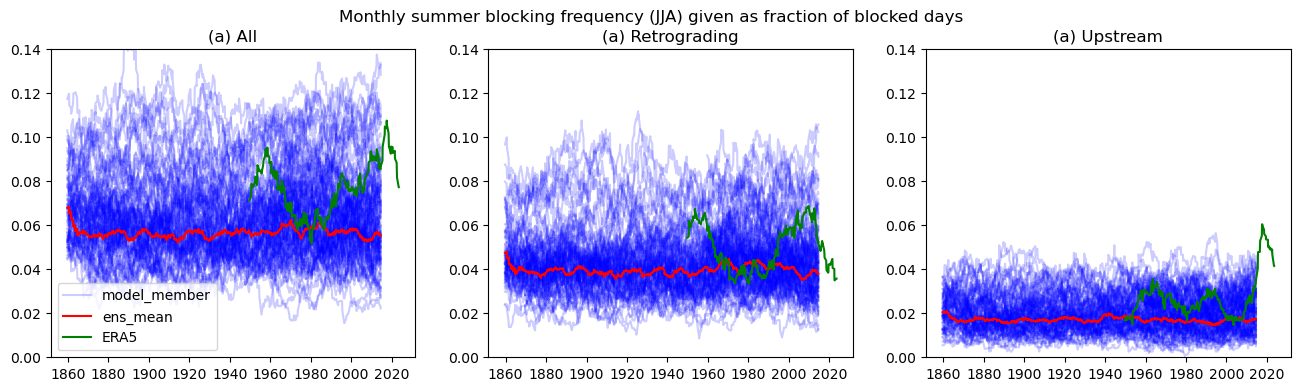

In [9]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']
widths = [2,0.6,0.6]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
plt.suptitle('Monthly summer blocking frequency (JJA) given as fraction of blocked days')

axes[0].set_title('(a) All')
for i,element in enumerate(dss_all):
    if i == 0:
        axes[0].plot(element['time'],(element['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color='blue',alpha=0.2,label='model_member')
    else:
        axes[0].plot(element['time'],(element['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color='blue',alpha=0.2)
axes[0].plot(average_all['time'],(average_all['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Red',label='ens_mean')
axes[0].plot(ERA5_all['time'],(ERA5_all['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Green',label='ERA5')
axes[0].legend()
axes[0].set_ylim(0,0.14)

axes[1].set_title('(a) Retrograding')
for element in dss_retrograding:
    axes[1].plot(element['time'],(element['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color='blue',alpha=0.2)
axes[1].plot(average_retrograding['time'],(average_retrograding['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Red')
axes[1].plot(ERA5_retrograding['time'],(ERA5_retrograding['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Green')
axes[1].set_ylim(0,0.14)

axes[2].set_title('(a) Upstream')
for element in dss_upstream:
    axes[2].plot(element['time'],(element['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color='blue',alpha=0.2)
axes[2].plot(average_upstream['time'],(average_upstream['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Red')
axes[2].plot(ERA5_upstream['time'],(ERA5_upstream['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Green')
axes[2].set_ylim(0,0.14)


(0.3, 3.5)

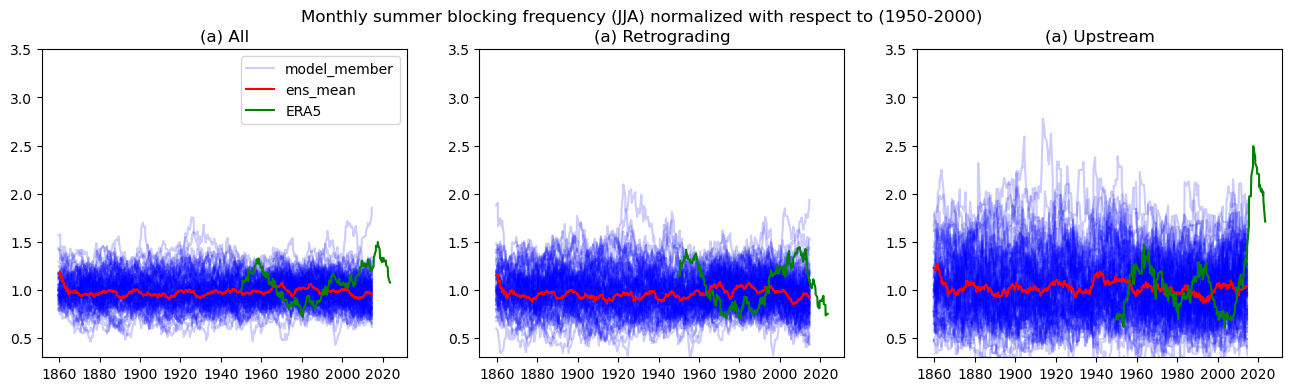

In [10]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
plt.suptitle('Monthly summer blocking frequency (JJA) normalized with respect to (1950-2000)')

axes[0].set_title('(a) All')
for i,element in enumerate(dss_all):
    if i == 0:
        axes[0].plot(element['time'],normalize(element['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color='blue',alpha=0.2,label='model_member')
    else:
        axes[0].plot(element['time'],normalize(element['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color='blue',alpha=0.2)
axes[0].plot(average_all['time'],normalize(average_all['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Red',label='ens_mean')
axes[0].plot(ERA5_all['time'],normalize(ERA5_all['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Green',label='ERA5')
axes[0].legend()
axes[0].set_ylim(0.3,+3.5)

axes[1].set_title('(a) Retrograding')
for element in dss_retrograding:
    axes[1].plot(element['time'],normalize(element['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color='blue',alpha=0.2)
axes[1].plot(average_retrograding['time'],normalize(average_retrograding['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Red')
axes[1].plot(ERA5_retrograding['time'],normalize(ERA5_retrograding['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Green')
axes[1].set_ylim(0.3,+3.5)

axes[2].set_title('(a) Upstream')
for element in dss_upstream:
    axes[2].plot(element['time'],normalize(element['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color='blue',alpha=0.2)
axes[2].plot(average_upstream['time'],normalize(average_upstream['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Red')
axes[2].plot(ERA5_upstream['time'],normalize(ERA5_upstream['DAV monthly blocking frequency']).rolling(time=3*10).mean('time'),color = 'Green')
axes[2].set_ylim(0.3,+3.5)


### FREQ VALUE ANALYSIS

In [11]:
da_all = []
for ds in dss_all:
    da_all.append(ds['DAV monthly blocking frequency'])

da_retrograding = []
for ds in dss_retrograding:
    da_retrograding.append(ds['DAV monthly blocking frequency'])

da_upstream = []
for ds in dss_upstream:
    da_upstream.append(ds['DAV monthly blocking frequency'])

In [12]:
print(ERA5_all['time'][0].values)

1940-06-30T06:00:00.000000000


In [13]:
from scipy.stats import linregress
from tqdm import tqdm

def select_reference_period(arr):
    start_date = '1931-06-30T12:00:00.000000000'
    end_date = '2014-07-31T12:00:00.000000000'
    return arr.loc[start_date:end_date]

def compute_freq_distribution(freq_list,n_months=3*10):
    freqs = []
    for elmnt in tqdm(freq_list):
        elmnt = select_reference_period(elmnt)
        elmnt = normalize(elmnt)
        running_mean = elmnt.rolling(time=n_months).mean('time')[n_months:]
        freqs.append(np.amax(running_mean))
        #print(np.amax(running_mean))
        #for freq in running_mean:
        #    freqs.append(freq)
    freqs_np_arr = np.array(freqs)
    return freqs_np_arr

def compute_ERA5_max_freq(freq,n_months=3*10):
    freq = normalize(freq)
    freq = freq.rolling(time=n_months).mean('time')[n_months:]
    freq_np_array = np.array(freq)
    return freq,np.amax(freq_np_array),np.argmax(freq_np_array)

In [14]:
n_months = 3*10

#apply to CMIP models -all
#compute distr
freq_np_arr_all = compute_freq_distribution(da_all)
#compute max ERA5 trend
da = ERA5_all['DAV monthly blocking frequency']
freq_ERA5_all,max_freq_all,idx_all = compute_ERA5_max_freq(da)

#apply to CMIP models -retrograding
#compute distr
freq_np_arr_retrograding = compute_freq_distribution(da_retrograding)
#compute max ERA5 trend
da = ERA5_retrograding['DAV monthly blocking frequency']
freq_ERA5_retrograding,max_freq_retrograding,idx_retrograding = compute_ERA5_max_freq(da)

#apply to CMIP models -upstream
#compute distr
freq_np_arr_upstream = compute_freq_distribution(da_upstream)
#compute max ERA5 trend
da = ERA5_upstream['DAV monthly blocking frequency']
freq_ERA5_upstream,max_freq_upstream,idx_upstream = compute_ERA5_max_freq(da)

100%|████████████████████████████████████████████████████████████████████| 108/108 [00:00<00:00, 199.10it/s]


(0.9, 2.8)

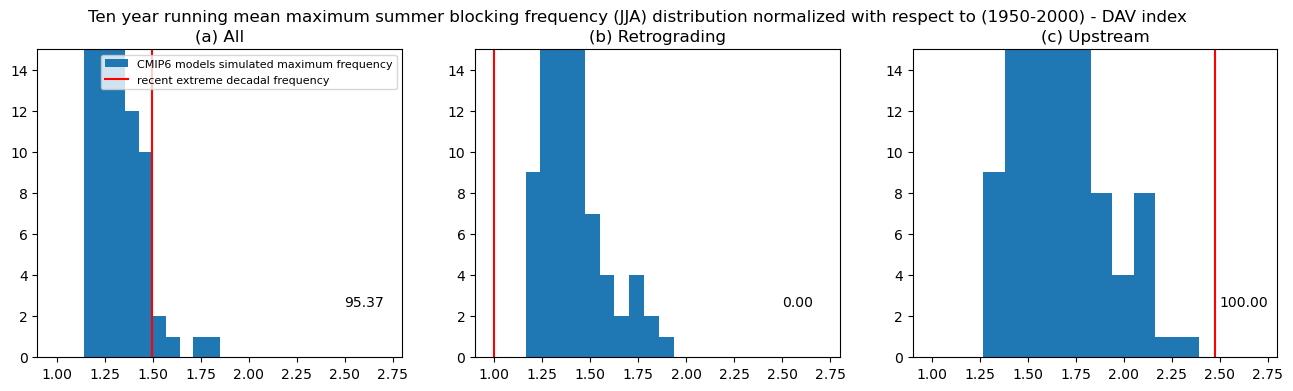

In [15]:
from scipy.stats import percentileofscore

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
plt.suptitle('Ten year running mean maximum summer blocking frequency (JJA) distribution normalized with respect to (1950-2000) - DAV index')

axes[0].set_title('(a) All')
axes[0].hist(freq_np_arr_all,label='CMIP6 models simulated maximum frequency')
axes[0].axvline(x=max_freq_all, color='red',label='recent extreme decadal frequency')#, linestyle='STYLE', linewidth=WIDTH)
axes[0].legend(fontsize=8)
percentile = percentileofscore(freq_np_arr_all,max_freq_all)
axes[0].text(2.5,2.5,f'{percentile:.2f}')
axes[0].set_ylim(0,15)
axes[0].set_xlim(0.9,2.8)

axes[1].set_title('(b) Retrograding')
axes[1].hist(freq_np_arr_retrograding)
axes[1].axvline(x=freq_ERA5_retrograding[idx_all], color='red',label='recent extreme decadal frequency')#, linestyle='STYLE', linewidth=WIDTH)
percentile = percentileofscore(freq_np_arr_retrograding,freq_ERA5_retrograding[idx_all])
axes[1].text(2.5,2.5,f'{percentile:.2f}')
axes[1].set_ylim(0,15)
axes[1].set_xlim(0.9,2.8)

axes[2].set_title('(c) Upstream')
axes[2].hist(freq_np_arr_upstream)
axes[2].axvline(x=freq_ERA5_upstream[idx_all], color='red',label='recent extreme ERA5 decadal frequency')#, linestyle='STYLE', linewidth=WIDTH)
percentile = percentileofscore(freq_np_arr_upstream,freq_ERA5_upstream[idx_all])
axes[2].text(2.5,2.5,f'{percentile:.2f}')
axes[2].set_ylim(0,15)
axes[2].set_xlim(0.9,2.8)


### TREND ANALYSIS

In [16]:
from scipy.stats import linregress
from tqdm import tqdm

def compute_trend_distribution(freq_list,n_months):
    trends = []
    for elmnt in tqdm(freq_list):
        ten_year_prds = elmnt.rolling(time=n_months)
        for i,ten_year_prd in enumerate(ten_year_prds): 
            if i > n_months:
                trend, _, _, _, _  = linregress(range(n_months),ten_year_prd[1])
                trends.append(trend)
    trends_np_arr = np.array(trends)
    return trends_np_arr,trends_np_arr.mean(),trends_np_arr.std()

def compute_ERA5_max_trend(freq,n_months):
    trends = []
    ten_year_prds = freq.rolling(time=n_months)
    for i,ten_year_prd in enumerate(ten_year_prds): 
        if i > n_months:
            trend, _, _, _, _  = linregress(range(n_months),ten_year_prd[1])
            trends.append(trend)
    trends_np_arr = np.array(trends)
    max_value = np.amax(trends_np_arr)
    #return the trends distribution, the max value and its index
    return trends,max_value,np.argmax(trends_np_arr) 

In [17]:
n_months = 3*10

#apply to CMIP models -all
#compute distr
trends_np_arr_all,mean,std = compute_trend_distribution(da_all,n_months=3*10)
#compute max ERA5 trend
da = ERA5_all['DAV monthly blocking frequency']
trends_ERA5_all,max_trend_all,max_idx_all = compute_ERA5_max_trend(da,n_months=n_months)

#apply to CMIP models -retrograding
#compute distr
trends_np_arr_retrograding,mean,std = compute_trend_distribution(da_retrograding,n_months=3*10)
#compute max ERA5 trend
da = ERA5_retrograding['DAV monthly blocking frequency']
trends_ERA5_retrograding,max_trend_retrograding,max_idx_retrograding = compute_ERA5_max_trend(da,n_months=n_months)

#apply to CMIP models -upstream
#compute distr
trends_np_arr_upstream,mean,std = compute_trend_distribution(da_upstream,n_months=3*10)
print(mean,std)
#compute max ERA5 trend
da = ERA5_upstream['DAV monthly blocking frequency']
trends_ERA5_upstream,max_trend_upstream,max_idx_upstream = compute_ERA5_max_trend(da,n_months=n_months)

100%|█████████████████████████████████████████████████████████████████████| 108/108 [01:14<00:00,  1.44it/s]


3.33230069616088e-06 0.0006801021284517678


In [18]:
print(max_idx_all)

2


Text(0.003, 1000, '81.83')

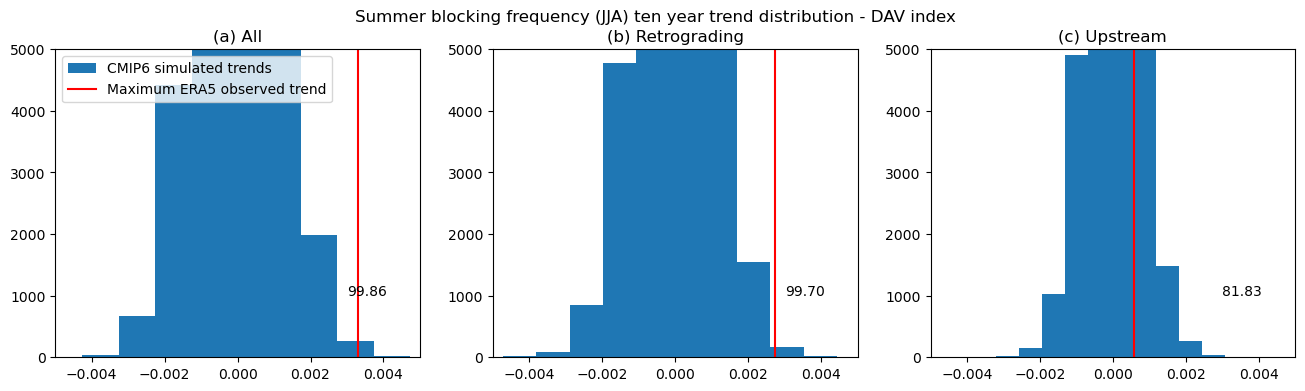

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
plt.suptitle('Summer blocking frequency (JJA) ten year trend distribution - DAV index')

axes[0].set_title('(a) All')
axes[0].hist(trends_np_arr_all,label='CMIP6 simulated trends')
axes[0].axvline(x=max_trend_all, color='red',label='Maximum ERA5 observed trend')#, linestyle='STYLE', linewidth=WIDTH)
axes[0].set_xlim(-0.005,0.005)
axes[0].set_ylim(0,5000)
percentile = percentileofscore(trends_np_arr_all,max_trend_all)
axes[0].text(0.003,1000,f'{percentile:.2f}')
axes[0].legend()

axes[1].set_title('(b) Retrograding')
axes[1].hist(trends_np_arr_retrograding)
axes[1].axvline(x=trends_ERA5_retrograding[max_idx_all], color='red')#, linestyle='STYLE', linewidth=WIDTH)
axes[1].set_xlim(-0.005,0.005)
axes[1].set_ylim(0,5000)
percentile = percentileofscore(trends_np_arr_retrograding,trends_ERA5_retrograding[max_idx_all])
axes[1].text(0.003,1000,f'{percentile:.2f}')

axes[2].set_title('(c) Upstream')
axes[2].hist(trends_np_arr_upstream)
axes[2].axvline(x=trends_ERA5_upstream[max_idx_all], color='red')#, linestyle='STYLE', linewidth=WIDTH)
axes[2].set_xlim(-0.005,0.005)
axes[2].set_ylim(0,5000)
percentile = percentileofscore(trends_np_arr_upstream,trends_ERA5_upstream[max_idx_all])
axes[2].text(0.003,1000,f'{percentile:.2f}')
